# Linear Regression Diagnostics

### Rebuild the modeling data and select features

The data preparation from the model notebook is repeated here in the same order so the results match. The 38 features are the ones chosen by backward, forward and stepwise selection, which all agreed on the same variables.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
df = pd.read_csv("../data/cleaned/listings_features.csv")

# Same preprocessing as the model notebook, in the same order, so the results match

# Drop rows with a missing target
df = df.dropna(subset=['log_price']).copy()

# Convert bathroom text to a number and a shared-bath flag
txt = df['bathrooms_text'].str.lower()
df['bathrooms'] = txt.str.extract(r'(\d+\.?\d*)')[0].astype(float)
df.loc[txt.str.contains('half', na=False) & df['bathrooms'].isnull(), 'bathrooms'] = 0.5
df['shared_bath'] = txt.str.contains('shared', na=False).astype(int)
df = df.drop(columns=['bathrooms_text'])

# Train/test split (same seed and size as the model notebook)
train, test = train_test_split(df, test_size=0.25, random_state=1234)

# Set target and drop non-predictors
X = train.drop(columns=['log_price', 'price_quote_price_per_night', 'price_outlier_flag']).copy()
y = train['log_price']

# Impute missing continuous values with train medians (saved for the test set later)
medians = {}
for col in X.select_dtypes(include='number').columns:
    if X[col].isnull().any():
        X[f'{col}_was_missing'] = X[col].isnull().astype(int)
        medians[col] = X[col].median()
        X[col] = X[col].fillna(medians[col])

# Dummy variables
X = pd.get_dummies(X, drop_first=True).astype(float)

# Keep the 38 features chosen by backward, forward and stepwise selection
selected_features = ['accommodates', 'bedrooms', 'minimum_nights', 'review_scores_rating', 'calculated_host_listings_count', 'has_license', 'amenity_count', 'has_pool', 'has_hot_tub', 'has_gym', 'has_game_room', 'pets_allowed', 'has_city_skyline_view', 'bathrooms', 'shared_bath', 'review_scores_rating_was_missing', 'host_is_superhost_t', 'neighbourhood_cleansed_District 13', 'neighbourhood_cleansed_District 15', 'neighbourhood_cleansed_District 16', 'neighbourhood_cleansed_District 17', 'neighbourhood_cleansed_District 19', 'neighbourhood_cleansed_District 2', 'neighbourhood_cleansed_District 26', 'neighbourhood_cleansed_District 29', 'neighbourhood_cleansed_District 33', 'neighbourhood_cleansed_District 34', 'neighbourhood_cleansed_District 5', 'neighbourhood_cleansed_District 9', 'distance_band_10+ km', 'distance_band_3-5 km', 'distance_band_5-10 km', 'room_type_grouped_Room', 'property_group_Guest Unit', 'property_group_Hotel/Resort', 'property_group_House', 'property_group_Other', 'property_group_Townhouse']
X_reduced = X[selected_features]

# Check
print(X_reduced.shape, y.shape)

(6147, 38) (6147,)


### Model from Stepwise Selection

In [5]:
import statsmodels.api as sm

# Subset the DataFrame to selected features
X_selected = X_reduced[selected_features].copy()
X_selected = sm.add_constant(X_selected)
model = sm.OLS(y, X_selected).fit()

# Summary with p-values, coefficients, R², etc.
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.627
Model:                            OLS   Adj. R-squared:                  0.625
Method:                 Least Squares   F-statistic:                     270.3
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:43:39   Log-Likelihood:                -2756.9
No. Observations:                6147   AIC:                             5592.
Df Residuals:                    6108   BIC:                             5854.
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
cons

### Residuals

In [6]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats

fitted = model.fittedvalues
residuals = model.resid
standardized_residuals = residuals / np.sqrt(model.mse_resid) 

### Lack-of-Fit

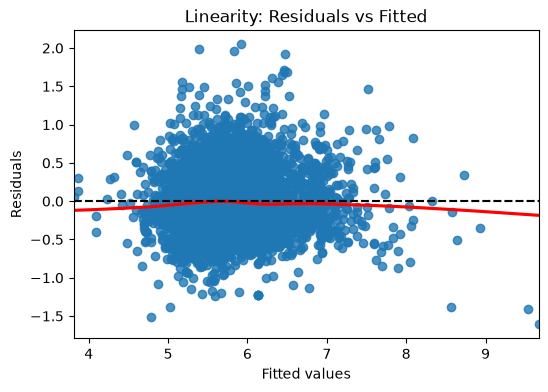

In [7]:
plt.figure(figsize=(6, 4))
sns.residplot(x=fitted, y=residuals, lowess=True, line_kws={'color': 'red'})
plt.axhline(0, linestyle='--', color='black')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Linearity: Residuals vs Fitted")
plt.show()

### Unequal Variance

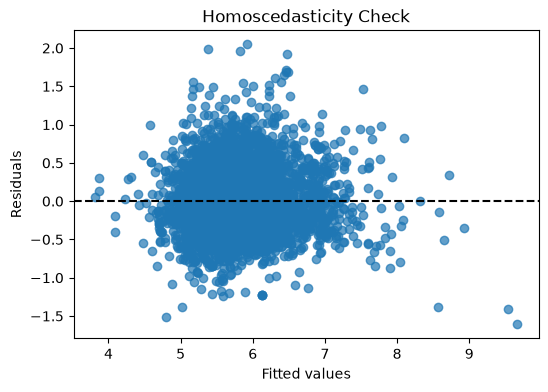

Breusch-Pagan test: p-value = 0.000


In [8]:
plt.figure(figsize=(6, 4))
plt.scatter(fitted, residuals, alpha=0.7)
plt.axhline(0, linestyle='--', color='black')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Homoscedasticity Check")
plt.show()

# Breusch-Pagan test
from statsmodels.stats.diagnostic import het_breuschpagan
bp_test = het_breuschpagan(residuals, model.model.exog)
print(f"Breusch-Pagan test: p-value = {bp_test[1]:.3f}")